# TRIAGE-Telco | Complete Integrated Group Notebook
### IT3091 Machine Learning · Guided Data Track · Group 2026-DS-07

**One notebook, four connected member stages, no external Python scripts.**

| Order | Owner | Main work | Notebook evidence |
|---|---|---|---|
| **Member 1** | **Jayasinghe S.S. · IT24102186** | Business framing, data quality, EDA, Disagreement Atlas | Churn patterns, correlation/associations, contradiction profiles |
| **Member 2** | **Imani H.A.I. · IT24102383** | Leakage-aware preprocessing, feature engineering and sensitivity | Transformation contract, ablation/imbalance experiments |
| **Member 3** | **A.H.Z. Ahmed · IT24102553** | Models, tuning, regularization, overfitting and predictive multiplicity | Saved 5-fold comparison plus newly fitted panel |
| **Member 4** | **H.A.S.R. Jayawardhana · IT24102243** | Decision threshold, ROC/PR/confusion matrices, business value | Frozen historical-test replay, contact capacity and risks |

**Research question:** Do similarly performing churn predictors disagree about individual customers, and does a transparent three-model vote improve practical contact prioritisation?

**What can be claimed:** The saved project found meaningful prediction disagreement. TRIAGE **did not show a reliable improvement** over ordinary risk ranking at equal contact capacity. The goal is **transparent decision support**, not deployment or causal claims.

> **How to run:** `Kernel → Restart & Run All`. Requires pandas, numpy, scipy, matplotlib, scikit-learn, imbalanced-learn, and CatBoost. This notebook reads the original CSV, saved folds, decision logs and recorded probabilities from the four folders in this submission. **No separate `.py` scripts are required, but keep the dataset and evidence folders beside the notebook.** The source dataset is also available at https://www.kaggle.com/datasets/blastchar/telco-customer-churn . Recomputed model fitting will take several minutes.

## 0 | Methodological boundaries and transparent reproducibility
- The **7,043-row historical EDA** is descriptive and included all customers; it must **not** be counted as untouched validation.
- The 5,634 development records and **five saved stratified folds** are fixed from the submitted ZIP. Learned preprocessing is fitted separately inside each fold.
- The 1,409 historical-test predictions below are **archived**, and had previously been exposed to analysis. They are used for **verification/replay**, not a newly selected, independent test.
- Hyperparameter searches are documented using the **archived grid results** (no exaggerated claim that every grid was rerun here). Actual 5-fold fits and three final full-development model fits execute below.
- The diagnostic disagreement threshold **0.50** and operational 3-model voting threshold **0.35** serve different purposes. The selected three-model policy stays frozen.
- Model agreement is **not** a calibrated probability of correctness; selecting customers for contact is **not** evidence an intervention prevents churn.

### 0.1 Python environment, source hashes and in-notebook evidence

In [1]:
from pathlib import Path
import hashlib, warnings, time, sys, platform
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone, BaseEstimator, TransformerMixin, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_validate
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score, recall_score, f1_score,
    brier_score_loss, confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
from scipy.stats import chi2_contingency
from catboost import CatBoostClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE=42
np.random.seed(RANDOM_STATE)
print('Python:',platform.python_version(),'| sklearn:',__import__('sklearn').__version__,'| CatBoost:',__import__('catboost').__version__)
print('No local Python scripts are imported; CSVs load from this submission.')

Python: 3.13.5 | sklearn: 1.8.0 | CatBoost: 1.2.8
No local Python scripts are imported; CSVs load from this submission.


In [2]:
# Load the original project files directly. Nothing is compressed or hidden in this notebook.
# Open the notebook from the submission root OR from final_notebook_code/.
from pathlib import Path

def locate_project_root():
    current = Path.cwd().resolve()
    candidates = [current, current.parent, current.parent.parent]
    for base in candidates:
        if (base / 'dataset' / 'raw' / 'WA_Fn-UseC_-Telco-Customer-Churn.csv').exists() and (base / 'model_method_comparison').is_dir():
            return base
    raise FileNotFoundError(
        'Project files not found. Extract the entire ZIP first, then run Jupyter from '
        'the submission folder or final_notebook_code folder. Do not open only the .ipynb.'
    )

PROJECT_ROOT = locate_project_root()
FILES = {
    'raw_csv': 'dataset/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv',
    'split': 'dataset/splits/split_membership.csv',
    'folds': 'dataset/splits/cv_fold_membership.csv',
    'dictionary': 'dataset/DATA_DICTIONARY.csv',
    'eda_log': 'decision_logs/member1/EDA_INSIGHT_LOG.csv',
    'prep_log': 'decision_logs/member2/preprocessing_decision_log.csv',
    'feature_log': 'decision_logs/member2/feature_registry.csv',
    'decision_log': 'decision_logs/project/CONSOLIDATED_DECISION_LOG.csv',
    'models_summary': 'model_method_comparison/MODEL_METHOD_COMPARISON.csv',
    'preprocess_pred': 'model_method_comparison/handoffs/member2_to_member3/OOF_preprocessing_predictions.csv',
    'oof': 'model_method_comparison/handoffs/member3_to_member4/candidate_models_updated_oof.csv',
    'stability': 'model_method_comparison/handoffs/member3_to_member4/customer_stability_integrated_development.csv',
    'generalization': 'model_method_comparison/results/member3/generalization_audit/model_generalization_summary.csv',
    'tolerance': 'model_method_comparison/results/member3/tables/near_optimal_tolerance_comparison.csv',
    'recorded_test': 'model_method_comparison/results/member4/final_test_probabilities_20261002_100144.csv',
    'scorecard': 'model_method_comparison/results/member4/final_test_scorecard.csv',
    'synthetic': 'dataset/examples/synthetic_customers.csv',
    'tc_treatment': 'model_method_comparison/results/member2/tables/totalcharges_treatment_results.csv',
    'balance': 'model_method_comparison/results/member2/tables/imbalance_arena_results.csv',
    'features': 'model_method_comparison/results/member2/tables/feature_ablation_results.csv',
    'demographic': 'model_method_comparison/results/member2/tables/data_minimization_results.csv',
}

def source_csv(name):
    '''Read one of the original recorded CSVs from the four submission folders.'''
    return pd.read_csv(PROJECT_ROOT / FILES[name])

raw = source_csv('raw_csv')
split = source_csv('split')
folds = source_csv('folds')
assert raw.shape == (7043, 21) and raw.customerID.is_unique
assert len(split) == len(raw) and len(folds) == 5634
print('Project folder:', PROJECT_ROOT)
print('Original Telco CSV:', FILES['raw_csv'])
print('Dataset size:', raw.shape, '| Development folds:', len(folds))
display(raw.head(3))


Project folder: /mnt/data/TRIAGE_Telco_FINAL_READABLE_SUBMISSION
Original Telco CSV: dataset/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv
Dataset size: (7043, 21) | Development folds: 5634


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


## 1 | Member 1 — Jayasinghe: business understanding and exploratory data analysis
**Responsibility:** Identify what one row means, check data quality, explain churn patterns and identify useful modelling hypotheses. EDA observations are **associations, not causes**. The source data are never overwritten.

**Decision lens:** Primary — stability-aware customer-retention support. Secondary — stable high-risk customer profiling, used to interpret the same primary decision.

In [3]:
eda = raw.copy()
eda['ChurnFlag'] = eda.Churn.eq('Yes').astype(int)
eda['TotalCharges_num'] = pd.to_numeric(eda.TotalCharges,errors='coerce')
blank = eda.TotalCharges.astype(str).str.strip().eq('')
quality = pd.DataFrame({'Check':['Customers','Original fields','Unique customer IDs','Exact duplicate rows','Churners','Churn share','Blank TotalCharges','Blank TotalCharges at tenure=0'],
 'Result':[len(eda),len(raw.columns),raw.customerID.nunique(),int(raw.duplicated().sum()),int(eda.ChurnFlag.sum()),f'{eda.ChurnFlag.mean():.2%}',int(blank.sum()),int((blank & eda.tenure.eq(0)).sum())]})
display(quality)
assert blank.sum()==11 and eda.loc[blank,'tenure'].eq(0).all()
print('Data-quality decision: 11 structural zero-tenure charge blanks require explicit treatment, not silent row deletion.')

,Check,Result
0,Customers,7043
1,Original fields,21
2,Unique customer IDs,7043
3,Exact duplicate rows,0
4,Churners,1869
5,Churn share,26.54%
6,Blank TotalCharges,11
7,Blank TotalCharges at tenure=0,11


Data-quality decision: 11 structural zero-tenure charge blanks require explicit treatment, not silent row deletion.


**EDA questions:** Which contract types churn more? How does tenure interact with charges? Does fiber-optic churn vary across contracts? These findings guide modelling, but the training pipeline must not be fitted on the complete dataset.

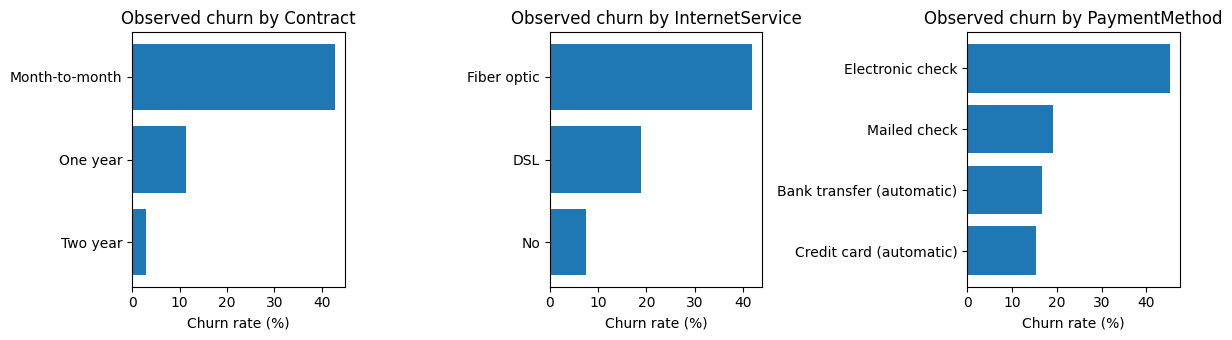

Contract,Month-to-month,One year,Two year
Internet service,,,
DSL,32.2,9.3,1.9
Fiber optic,54.6,19.3,7.2
No,18.9,2.5,0.8


In [4]:
fig,ax=plt.subplots(1,3,figsize=(12,3.5))
for a,col in zip(ax,['Contract','InternetService','PaymentMethod']):
 rates=eda.groupby(col).ChurnFlag.agg(['mean','size']).sort_values('mean',ascending=False)
 a.barh(rates.index.astype(str),rates['mean']*100)
 a.invert_yaxis();a.set_title(f'Observed churn by {col}');a.set_xlabel('Churn rate (%)')
plt.tight_layout();plt.show()
relationship=eda.pivot_table(index='InternetService',columns='Contract',values='ChurnFlag',aggfunc='mean')
display((relationship*100).round(1).rename_axis('Internet service'))

**Correlation and categorical associations.** Pearson correlation is appropriate for numeric measurements; many service/contract fields are categorical, so their association strength is shown using bias-corrected Cramér’s V. Correlation and association are **not causal evidence**.

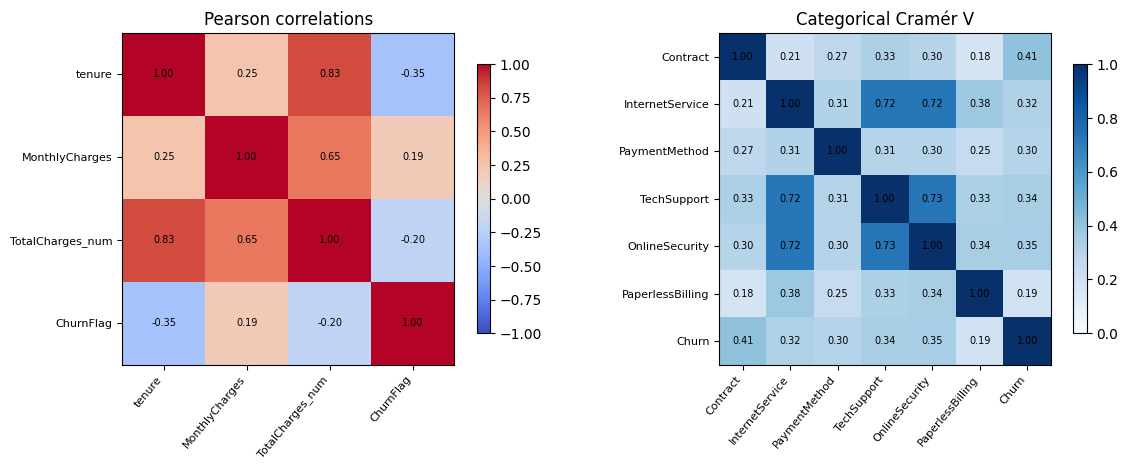

tenure vs TotalCharges Pearson: 0.826 | Contract vs Churn Cramér V: 0.41


In [5]:
numeric=eda[['tenure','MonthlyCharges','TotalCharges_num','ChurnFlag']].corr()
def cramers_v(a,b):
    tab=pd.crosstab(a,b)
    chi2=chi2_contingency(tab,correction=False)[0]; n=tab.to_numpy().sum()
    phi2=chi2/n; r,k=tab.shape
    phi2corr=max(0,phi2-(k-1)*(r-1)/(n-1))
    rcorr=r-(r-1)**2/(n-1);kcorr=k-(k-1)**2/(n-1)
    return np.sqrt(phi2corr/max(min(kcorr-1,rcorr-1),1e-15))
cats=['Contract','InternetService','PaymentMethod','TechSupport','OnlineSecurity','PaperlessBilling','Churn']
cvmat=pd.DataFrame([[cramers_v(eda[a],eda[b]) for b in cats] for a in cats],index=cats,columns=cats)
fig,axs=plt.subplots(1,2,figsize=(12,4.8))
for axis,mat,title,vmax in [(axs[0],numeric,'Pearson correlations',1),(axs[1],cvmat,'Categorical Cramér V',1)]:
 img=axis.imshow(mat,vmin=-1 if title.startswith('Pearson') else 0,vmax=vmax,cmap='coolwarm' if title.startswith('Pearson') else 'Blues')
 axis.set_xticks(range(len(mat)));axis.set_xticklabels(mat.columns,rotation=50,ha='right',fontsize=8)
 axis.set_yticks(range(len(mat)));axis.set_yticklabels(mat.index,fontsize=8)
 for (i,j),x in np.ndenumerate(mat.to_numpy()):axis.text(j,i,f'{x:.2f}',ha='center',va='center',fontsize=7)
 axis.set_title(title);fig.colorbar(img,ax=axis,fraction=.03)
plt.tight_layout();plt.show()
print('tenure vs TotalCharges Pearson:',round(numeric.loc['tenure','TotalCharges_num'],3),'| Contract vs Churn Cramér V:',round(cvmat.loc['Contract','Churn'],3))

In [6]:
eda_log=source_csv('eda_log')
dictionary=source_csv('dictionary')
display(dictionary.head(8))
display(eda_log.head(6))

,column,meaning,raw_dtype,n_unique,role,allowed_use,sample_values,caveat
0,customerID,Unique customer identifier,object,7043,Identifier,Join/tracking only,7590-VHVEG | 5575-GNVDE | 3668-QPYBK | 7795-CF...,Do not use as a behavioural predictor.
1,gender,Customer gender,object,2,Demographic/context,Predictor in full reference; data-minimisation...,Female | Male,Do not treat as an actionable retention lever.
2,SeniorCitizen,Senior-citizen indicator (0/1),int64,2,Demographic/context,Predictor in full reference; data-minimisation...,0 | 1,Conceptually categorical although stored as in...
3,Partner,Whether the customer has a partner,object,2,Customer profile,Predictor candidate,Yes | No,Association is not causal.
4,Dependents,Whether the customer has dependents,object,2,Customer profile,Predictor candidate,No | Yes,Association is not causal.
5,tenure,Months with the provider,int64,73,Relationship/history,Predictor candidate,1 | 34 | 2 | 45 | 8 | 22,History variable; cannot be changed retroactiv...
6,PhoneService,Whether phone service is active,object,2,Service,Predictor candidate,No | Yes,Upstream service state.
7,MultipleLines,Multiple phone lines status,object,3,Service,Predictor candidate,No phone service | No | Yes,"""No phone service"" is structural, not missing."


,ID,Question,Population_n,Evidence,Insight,Caveat,Next_action,Confidence
0,EDA-01,Does contract relate to churn?,7043,Churn rate + n by Contract; Wilson CI; bootstr...,Month-to-month churn=42.7% vs Two-year=2.8%.,Contract is related to tenure/service mix; ass...,Retain for modelling; interpret jointly with t...,HIGH
1,EDA-02,Are new customers riskier?,7043,Tenure-band churn rates + churn-group numeric ...,0-6 month churn=52.9%; 49-72 month churn=9.5%.,EDA band cut-points are analyst choices.,Keep tenure continuous for modelling; bands ar...,HIGH
2,EDA-03,Does payment method identify risk?,7043,Overall PaymentMethod rates + Contract×Payment...,Electronic check overall churn=45.3%; relation...,Payment method may reflect self-selection/cust...,Let Member 2 preserve category meaning; Member...,HIGH
3,EDA-04,Does Fiber optic context matter?,7043,InternetService rates + Contract×InternetServi...,"Fiber optic overall churn=41.9%, but absolute ...",Internet service may proxy service package/cha...,Test interaction-sensitive models; avoid a one...,HIGH
4,EDA-05,Is TechSupport associated with churn?,7043,TechSupport churn rates + bootstrap contrast,TechSupport=No churn=41.6% vs Yes=15.2%.,"""No internet service"" is a separate structural...",Preserve structural categories; test SupportGa...,HIGH
5,EDA-06,How do numeric customer histories differ by ch...,7043,Median/mean numeric summary by Churn + boxplots,Median tenure: churners=10m vs non-churners=38...,TotalCharges is confounded by tenure; lower cu...,Member 2 should keep numeric meaning and test ...,HIGH


### 1.1 Mixed-signal profiles + uncertainty
Example: fiber-optic service is often associated with higher churn, while two-year contracts are associated with lower churn. Both can describe the **same person**. Compare their actual historic rates before assigning a simplistic rule.

In [7]:
fiber=eda.InternetService.eq('Fiber optic'); two_year=eda.Contract.eq('Two year')
from math import sqrt

def wilson(k,n,z=1.96):
    p=k/n; den=1+z*z/n
    center=(p+z*z/(2*n))/den
    half=z*sqrt((p*(1-p)+z*z/(4*n))/n)/den
    return max(0,center-half),min(1,center+half)
rows=[]
for name,mask in [('All fiber optic',fiber),('Fiber optic + two year contract',fiber & two_year),('All month-to-month',eda.Contract.eq('Month-to-month'))]:
 n=int(mask.sum());k=int(eda.loc[mask,'ChurnFlag'].sum());lo,hi=wilson(k,n)
 rows.append([name,n,k,round(k/n,4),round(lo,4),round(hi,4)])
display(pd.DataFrame(rows,columns=['Customer profile','n','churners','observed rate','Wilson low','Wilson high']))
print('Note: these are historical subgroup associations; searching many groups can produce chance patterns.')

,Customer profile,n,churners,observed rate,Wilson low,Wilson high
0,All fiber optic,3096,1297,0.4189,0.4017,0.4364
1,Fiber optic + two year contract,429,31,0.0723,0.0514,0.1007
2,All month-to-month,3875,1655,0.4271,0.4116,0.4427


Note: these are historical subgroup associations; searching many groups can produce chance patterns.


## 2 | Member 2 — Imani: preprocessing, feature engineering and leakage prevention
**Responsibility:** Convert raw inputs into valid model features without learning preprocessing statistics from validation customers. The complete modelling functions are **inside this notebook** — no `pipeline_contract.py` import.

Important preserved rules: `customerID` and `Churn` never enter the predictor matrix; the 11 empty `TotalCharges` are legitimate only at `tenure=0`; no structural service category is treated as ordinary missingness; encoders/scalers are fitted within each training fold.

In [8]:
RAW_FEATURES=['gender','SeniorCitizen','Partner','Dependents','tenure','PhoneService','MultipleLines','InternetService',
    'OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies','Contract',
    'PaperlessBilling','PaymentMethod','MonthlyCharges','TotalCharges']
NUMERIC=['SeniorCitizen','tenure','MonthlyCharges','TotalCharges']
CATEGORICAL=[x for x in RAW_FEATURES if x not in NUMERIC]

def semantic_repair(X):
    if not isinstance(X,pd.DataFrame):raise TypeError('Require DataFrame')
    if list(X.columns)!=RAW_FEATURES: raise ValueError('Expected exactly 19 allowed predictors, in registered order')
    if X.columns.duplicated().any():raise ValueError('Duplicated feature')
    data=X.copy(); original=data['TotalCharges']
    blanks=original.isna() | original.astype(str).str.strip().eq('')
    data['TotalCharges']=pd.to_numeric(original,errors='coerce')
    if data['TotalCharges'].isna().sum()!=blanks.sum():raise ValueError('Nonblank invalid TotalCharges')
    if not data.loc[blanks,'tenure'].eq(0).all():raise ValueError('Structural zero requires tenure zero')
    for col in NUMERIC:
        vals=pd.to_numeric(data[col],errors='raise')
        if (vals.dropna()<0).any() or not np.isfinite(vals.dropna()).all():raise ValueError('Invalid numeric value '+col)
        data[col]=vals
    return data

class TelcoSemanticTransformer(BaseEstimator, TransformerMixin):
    def __init__(self,native=False):self.native=native
    def fit(self,X,y=None):
        semantic_repair(X); self.n_features_in_=X.shape[1]
        return self
    def transform(self,X):
        data=semantic_repair(X)
        if self.native:
            data['TotalCharges']=data['TotalCharges'].fillna(0)
            if data.isna().any().any():raise ValueError('Unhandled CatBoost native missing value')
            for c in CATEGORICAL:data[c]=data[c].astype(str)
        return data

def preprocessing(scaling=True,totalcharges='zero'):
    if totalcharges not in ('zero','median'):raise ValueError(totalcharges)
    numeric_processor=Pipeline([('imputer',SimpleImputer(strategy='median'))] + ([('scaler',StandardScaler())] if scaling else []))
    charge_processor=Pipeline([('imputer',SimpleImputer(strategy='constant',fill_value=0) if totalcharges=='zero' else SimpleImputer(strategy='median'))] + ([('scaler',StandardScaler())] if scaling else []))
    categoricals=Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))])
    return ColumnTransformer([('nums',numeric_processor,['SeniorCitizen','tenure','MonthlyCharges']),
                              ('charges',charge_processor,['TotalCharges']),('categorical',categoricals,CATEGORICAL)])

def make_pipeline(estimator,scaling=False,balance='none',totalcharges='zero'):
    steps=[('semantic',TelcoSemanticTransformer()),('prepare',preprocessing(scaling,totalcharges))]
    if balance=='ros':steps.append(('sampler',RandomOverSampler(random_state=42)))
    est=clone(estimator)
    if balance=='weighted':est.set_params(class_weight='balanced')
    return ImbPipeline(steps+[('model',est)])

def make_cb():
    return CatBoostClassifier(iterations=500,depth=4,learning_rate=.03,loss_function='Logloss',
        random_seed=42,thread_count=2,verbose=False,allow_writing_files=False,
        cat_features=CATEGORICAL)

class NativeCatBoostClassifier(ClassifierMixin, BaseEstimator):
    # sklearn-compatible wrapper: CatBoost 1.2.8 lacks tags required by sklearn 1.8 Pipeline.
    # Fit still uses precisely the project's native categorical pathway.
    def __init__(self, iterations=500, depth=4, learning_rate=.03, random_seed=42):
        self.iterations=iterations;self.depth=depth;self.learning_rate=learning_rate;self.random_seed=random_seed
    def fit(self,X,y):
        self.prep_=TelcoSemanticTransformer(native=True).fit(X)
        prepared=self.prep_.transform(X)
        self.estimator_=CatBoostClassifier(iterations=self.iterations,depth=self.depth,
            learning_rate=self.learning_rate,loss_function='Logloss',random_seed=self.random_seed,
            thread_count=2,verbose=False,allow_writing_files=False)
        self.estimator_.fit(prepared,y,cat_features=CATEGORICAL)
        self.classes_=np.array([0,1]);return self
    def predict_proba(self,X):
        return self.estimator_.predict_proba(self.prep_.transform(X))
    def predict(self,X):
        return (self.predict_proba(X)[:,1]>=.5).astype(int)

def make_cat_pipeline():
    return NativeCatBoostClassifier()

membership=split.set_index('customerID').loc[raw.customerID]
assert membership.Split.value_counts().to_dict()=={'Development':5634,'FinalTest_LOCKED':1409}
fold_order=folds.sort_values('DevelopmentOrder').customerID
by_id=raw.set_index('customerID')
X_dev=by_id.loc[fold_order,RAW_FEATURES].reset_index(drop=True)
y_dev=by_id.loc[fold_order,'Churn'].eq('Yes').astype(int).reset_index(drop=True)
fold_idx=folds.set_index('customerID').loc[fold_order,'Fold'].to_numpy()
cv_splits=[(np.where(fold_idx!=i)[0],np.where(fold_idx==i)[0]) for i in range(5)]
assert len(X_dev)==5634 and set(fold_idx)==set(range(5))
print('Leakage-aware source:',X_dev.shape,'| five frozen folds:', [len(v) for _,v in cv_splits]);
display(X_dev.head(2))

Leakage-aware source: (5634, 19) | five frozen folds: [1127, 1127, 1127, 1127, 1126]


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Male,0,No,No,35,No,No phone service,DSL,No,No,Yes,No,Yes,Yes,Month-to-month,No,Electronic check,49.2,1701.65
1,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,75.1,1151.55


### 2.1 Treatment and balancing decisions
The recorded experiments compared structural-zero vs median charging imputation, and no balancing vs class weights vs training-fold random oversampling. Mean-fold AP and recall can favor different decisions. Tables below are **recorded evidence from the submitted member notebook**.

In [9]:
display(source_csv('tc_treatment'))
display(source_csv('balance'))
print('Default: zero treatment only after tenure check; keep original class proportions because recorded AP comparison did not improve with balancing.')
# Prove safety of the transform on held-out fold, rather than reusing fitted preprocessing.
train_idx,valid_idx=cv_splits[0]
safe=make_pipeline(LogisticRegression(max_iter=2000,random_state=42),scaling=True)
safe.fit(X_dev.iloc[train_idx],y_dev.iloc[train_idx]); hold_proba=safe.predict_proba(X_dev.iloc[valid_idx])[:,1]
print('Successfully fit preprocessing inside fold 0; held-out AP:',round(average_precision_score(y_dev.iloc[valid_idx],hold_proba),4))

,Treatment,pr_auc,roc_auc,f1,precision,recall,delta_vs_best_pr_auc
0,MEDIAN,0.661430,0.846137,0.592316,0.652899,0.543144,-0.000226
1,MEDIAN+IND,0.661636,0.846203,0.592412,0.652094,0.543813,-0.000020
2,ZERO,0.661656,0.846201,0.592329,0.652927,0.543144,0.000000
3,ZERO+IND,0.661607,0.846219,0.592090,0.652304,0.543144,-0.000049


,Strategy,pr_auc,roc_auc,f1,precision,recall
0,BAL-0,0.661656,0.846201,0.592329,0.652927,0.543144
1,BAL-W,0.659985,0.845953,0.628257,0.516933,0.801338
2,BAL-ROS,0.658750,0.845744,0.627451,0.515870,0.801338


Default: zero treatment only after tenure check; keep original class proportions because recorded AP comparison did not improve with balancing.


Successfully fit preprocessing inside fold 0; held-out AP: 0.6439


### 2.2 Engineered telecom features (tested, not automatically retained)
`ServiceCount`, `SupportGap`, `AutoPay` and `ChargePerService` were tested by adding them to a linear baseline. They did **not** improve the recorded AP, so the final model uses the 19 raw features. Retaining a negative result is important evidence.

In [10]:
def engineered_features(df):
    x=semantic_repair(df)
    addons=['OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']
    internet=x.InternetService.ne('No')
    count=x.PhoneService.eq('Yes').astype(int)+x.MultipleLines.eq('Yes').astype(int)+internet.astype(int)
    for col in addons:count=count+x[col].eq('Yes').astype(int)
    x['ServiceCount']=count
    x['SupportGap']=np.where(internet,x[['OnlineSecurity','DeviceProtection','TechSupport']].eq('No').sum(axis=1),0)
    x['AutoPay']=x.PaymentMethod.isin(['Bank transfer (automatic)','Credit card (automatic)']).astype(int)
    x['ChargePerService']=x.MonthlyCharges/x.ServiceCount.clip(lower=1)
    return x
print('Examples of deterministic engineered features:')
display(engineered_features(X_dev.head(3))[['ServiceCount','SupportGap','AutoPay','ChargePerService']])
display(source_csv('features'))
display(source_csv('demographic'))
print('The demographic-reduction comparison is an input-minimization experiment, not a fairness proof.')

Examples of deterministic engineered features:


,ServiceCount,SupportGap,AutoPay,ChargePerService
0,4,2,0,12.300000
1,3,2,0,25.033333
2,4,1,0,10.137500


,pr_auc,roc_auc,f1,precision,recall,FeatureSet,delta_pr_auc,Decision
0,0.661656,0.846201,0.592329,0.652927,0.543144,BASE,0.000000,REFERENCE
1,0.661580,0.846190,0.592114,0.652405,0.543144,BASE + ServiceCount,-0.000076,EXPERIMENTAL_NOT_DEFAULT
2,0.661533,0.846190,0.593054,0.653705,0.543813,BASE + SupportGap,-0.000123,EXPERIMENTAL_NOT_DEFAULT
3,0.661510,0.846137,0.591798,0.652611,0.542475,BASE + AutoPay,-0.000146,EXPERIMENTAL_NOT_DEFAULT
4,0.660973,0.845979,0.593718,0.652330,0.545819,BASE + ChargePerService,-0.000683,EXPERIMENTAL_NOT_DEFAULT
5,0.660977,0.845983,0.593538,0.651839,0.545819,BASE + ALL_ENGINEERED,-0.000679,EXPERIMENTAL_NOT_DEFAULT


,FeatureSet,pr_auc,roc_auc,f1,precision,recall,delta_pr_auc_vs_full
0,FS-RAW-FULL,0.661656,0.846201,0.592329,0.652927,0.543144,0.000000
1,FS-RAW-NOGENDER,0.660835,0.846145,0.594677,0.654691,0.545819,-0.000821
2,FS-RAW-LIGHT-DEMO,0.661672,0.846283,0.598212,0.657589,0.549833,0.000015
3,FS-RAW-NO-PROFILE,0.660117,0.846046,0.601222,0.655932,0.555853,-0.001539


The demographic-reduction comparison is an input-minimization experiment, not a fairness proof.


### 2.3 Customer-level preprocessing sensitivity
The original development-only OOF comparison held Logistic Regression and folds fixed while changing the imbalance policy. This is **not** the final 0.35 decision rule; the experiment used a 0.50 diagnostic threshold.

In [11]:
pre_p=source_csv('preprocess_pred').set_index('customerID').loc[fold_order].reset_index()
assert (pre_p.customerID.to_numpy()==fold_order.to_numpy()).all()
prep_unstable=pre_p['prep_any_disagreement'].astype(bool)
assert int(prep_unstable.sum())==1114
print(f'Development customers with disagreement across imbalance policies: {prep_unstable.sum()} / {len(pre_p)} ({prep_unstable.mean():.2%})')
display(pre_p[['customerID','pred_BAL-0','pred_BAL-W','pred_BAL-ROS','PrepStabilityFlag']].head(5))

Development customers with disagreement across imbalance policies: 1114 / 5634 (19.77%)


,customerID,pred_BAL-0,pred_BAL-W,pred_BAL-ROS,PrepStabilityFlag
0,4950-BDEUX,0,1,1,Sensitive
1,7993-NQLJE,0,1,1,Sensitive
2,7321-ZNSLA,0,0,0,Stable
3,4922-CVPDX,0,0,0,Stable
4,2903-YYTBW,0,1,1,Sensitive


## 3 | Member 3 — Ahmed: baseline, alternatives, tuning and predictive multiplicity
**Responsibility:** Compare Logistic Regression with alternative algorithms using the saved development folds, test plausible settings, analyze train/validation gaps and measure when near-performing models disagree.

**Metric:** average precision (AP). The positive churn class is about 26.5% of the source records. The five-fold **mean AP** and pooled OOF AP are different aggregations. These estimates reuse folds for some model selection; they are not nested-CV estimates.

In [12]:
model_defs={
    'Logistic Regression':make_pipeline(LogisticRegression(max_iter=2000,random_state=42),scaling=True),
    'Decision Tree':make_pipeline(DecisionTreeClassifier(max_depth=5,random_state=42)),
    'Random Forest':make_pipeline(RandomForestClassifier(n_estimators=200,min_samples_leaf=5,random_state=42,n_jobs=1)),
    'Tuned Random Forest':make_pipeline(RandomForestClassifier(n_estimators=200,max_depth=10,min_samples_leaf=10,random_state=42,n_jobs=1)),
    'Gradient Boosting':make_pipeline(GradientBoostingClassifier(n_estimators=100,learning_rate=.05,max_depth=3,random_state=42)),
    'CatBoost':make_cat_pipeline(),
}
print('Model families:', ', '.join(model_defs))
print('Actual scikit-learn/ CatBoost fitting is done in subsequent cells; archived tuning history is not presented as newly searched.')

Model families: Logistic Regression, Decision Tree, Random Forest, Tuned Random Forest, Gradient Boosting, CatBoost
Actual scikit-learn/ CatBoost fitting is done in subsequent cells; archived tuning history is not presented as newly searched.


### 3.1 Recompute the five-fold candidate comparison
This cell **trains actual models** in the notebook and produces **new five-fold OOF predictions**, with preprocessing fitted inside folds. It will take a few minutes on a normal laptop. We compare our fresh scores with the frozen recorded scores rather than silently changing model policy. The initial (untuned) CatBoost record is kept in the archived results; the trained CatBoost here uses the final tuned configuration.

In [13]:
t0=time.time(); oof_new=pd.DataFrame({'customerID':fold_order.to_numpy(),'ActualChurn':y_dev.to_numpy(),'Fold':fold_idx})
model_rows=[]
for name,est in model_defs.items():
    scores=[]; preds=np.full(len(y_dev),np.nan)
    for fold,(tr,va) in enumerate(cv_splits):
        m=clone(est);m.fit(X_dev.iloc[tr],y_dev.iloc[tr]);p=m.predict_proba(X_dev.iloc[va])[:,1]
        assert np.isfinite(p).all();preds[va]=p
        scores.append(average_precision_score(y_dev.iloc[va],p))
    assert np.isfinite(preds).all()
    oof_new['prob_'+name.replace(' ','_')]=preds
    model_rows.append({'Model':name,'NewMeanFoldAP':np.mean(scores),'NewFoldSD':np.std(scores,ddof=1),'NewPooledOOFAP':average_precision_score(y_dev,preds)})
    print(f'{name}: mean AP {np.mean(scores):.4f} | {time.time()-t0:.0f}s elapsed',flush=True)
recomputed_cv=pd.DataFrame(model_rows)
display(recomputed_cv.round(5))
print('Total full five-fold run time (s):',round(time.time()-t0,1))

Logistic Regression: mean AP 0.6617 | 1s elapsed


Decision Tree: mean AP 0.6140 | 1s elapsed


Random Forest: mean AP 0.6575 | 5s elapsed


Tuned Random Forest: mean AP 0.6639 | 10s elapsed


Gradient Boosting: mean AP 0.6722 | 14s elapsed


CatBoost: mean AP 0.6727 | 35s elapsed


,Model,NewMeanFoldAP,NewFoldSD,NewPooledOOFAP
0,Logistic Regression,0.66166,0.02164,0.65852
1,Decision Tree,0.61395,0.02582,0.61901
2,Random Forest,0.65746,0.02395,0.65394
3,Tuned Random Forest,0.66386,0.02047,0.66051
4,Gradient Boosting,0.67218,0.02332,0.66854
5,CatBoost,0.67273,0.02397,0.66934


Total full five-fold run time (s): 34.7


### 3.2 Compare to archived model selection and hyperparameter searches
The code notebooks in the ZIP documented **GridSearchCV** of Logistic Regression C, Random Forest depth/leaf size, and Gradient Boosting learning rate/depth, plus a manual CatBoost search. This consolidated version displays their saved results and retained settings; it does not misleadingly claim to execute those complete hyperparameter grids again.

**Note:** The original grid-search outcomes are replayed from saved result tables. They are not rerun in this combined notebook, so do not interpret them as freshly executed searches.

In [14]:
recorded_models=source_csv('models_summary')
display(recorded_models[['model','mean_fold_average_precision','fold_sd','pooled_oof_average_precision']].head(7).round(5))
print('Documented settings: LR C=1; RF depth=10, leaf=10, 200 trees; GB lr=0.05, depth=3, 100 trees; CB depth=4, lr=0.03, 500 iterations.')
print('Recorded best mean-fold AP: CatBoost 0.672731 vs Gradient Boosting 0.672183 (gap 0.000548).')
# Recognize the initial CatBoost row is not the tuned configuration fitted above.
for label in ['Logistic Regression','Decision Tree','Random Forest','Tuned Random Forest','Gradient Boosting']:
 rr=recorded_models.loc[recorded_models['model'].eq(label)]
 cc=recomputed_cv.loc[recomputed_cv.Model.eq(label)]
 if len(rr)==1:print(label,'| new - recorded mean AP:',round(float(cc.NewMeanFoldAP.iloc[0]-rr.mean_fold_average_precision.iloc[0]),6))

,model,mean_fold_average_precision,fold_sd,pooled_oof_average_precision
0,Logistic Regression,0.66166,0.02164,0.65852
1,Decision Tree,0.61395,0.02582,0.61901
2,Random Forest,0.65746,0.02395,0.65394
3,Gradient Boosting,0.67218,0.02332,0.66854
4,Tuned Random Forest,0.66386,0.02047,0.66051
5,CatBoost,0.66912,0.02401,0.66479
6,Tuned CatBoost,0.67273,0.02397,0.66934


Documented settings: LR C=1; RF depth=10, leaf=10, 200 trees; GB lr=0.05, depth=3, 100 trees; CB depth=4, lr=0.03, 500 iterations.
Recorded best mean-fold AP: CatBoost 0.672731 vs Gradient Boosting 0.672183 (gap 0.000548).
Logistic Regression | new - recorded mean AP: 0.0
Decision Tree | new - recorded mean AP: 0.0
Random Forest | new - recorded mean AP: 0.0
Tuned Random Forest | new - recorded mean AP: 0.0
Gradient Boosting | new - recorded mean AP: 0.0


### 3.3 Near-optimal panel and generalization audit
Model selection kept candidates within an **absolute 0.010 mean-fold AP gap** of CatBoost's best recorded score. This was an explored development criterion (not a prespecified statistical equivalence test). It admitted tuned CatBoost, Gradient Boosting and tuned Random Forest. **Random Forest showed a larger train–validation gap**, so it is included as a different modelling family *with an explicit overfitting caveat*.

,Model,MeanAveragePrecision,GapFromBest,Within_0.005,Within_0.010,Within_0.015
0,Tuned CatBoost,0.672731,0.000000,True,True,True
1,Gradient Boosting,0.672183,0.000548,True,True,True
2,Tuned Random Forest,0.663856,0.008875,False,True,True
3,Logistic Regression,0.661656,0.011075,False,False,True
4,Decision Tree,0.613955,0.058776,False,False,False


,Model,TrainPR_AUC,ValidationPR_AUC,MeanGap
0,Logistic Regression L2 (frozen baseline),0.6672,0.6617,0.0055
1,Logistic Regression L1 (exploratory),0.6674,0.6617,0.0056
2,"RBF SVM (exploratory, uncalibrated)",0.7123,0.6374,0.0749
3,Tuned Random Forest (frozen settings),0.7591,0.6639,0.0953
4,Gradient Boosting (frozen settings),0.7190,0.6722,0.0469
5,Tuned CatBoost (frozen settings),0.7099,0.6727,0.0372


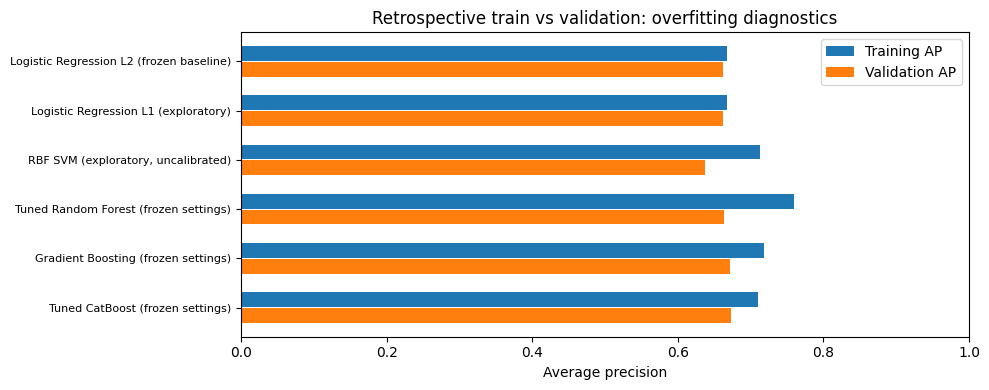

L1 and L2 LR showed similar validation AP (~0.6617). Exploratory RBF SVM achieved ~0.6374. They did not replace the original panel.


In [15]:
display(source_csv('tolerance'))
trainval=source_csv('generalization')
display(trainval[['Model','TrainPR_AUC','ValidationPR_AUC','MeanGap']].round(4))
fig,ax=plt.subplots(figsize=(10,4))
idx=np.arange(len(trainval));ax.barh(idx-.16,trainval.TrainPR_AUC,height=.30,label='Training AP');ax.barh(idx+.16,trainval.ValidationPR_AUC,height=.30,label='Validation AP')
ax.set_yticks(idx,trainval.Model,fontsize=8);ax.invert_yaxis();ax.set_xlim(0,1);ax.set_xlabel('Average precision');ax.legend();ax.set_title('Retrospective train vs validation: overfitting diagnostics');plt.tight_layout();plt.show()
print('L1 and L2 LR showed similar validation AP (~0.6617). Exploratory RBF SVM achieved ~0.6374. They did not replace the original panel.')

### 3.4 Four independent sources of customer-level disagreement (archived OOF evidence)
The **four-family diagnostic** includes Logistic Regression, Gradient Boosting, tuned Random Forest and tuned CatBoost, evaluated at 0.50. It differs from the **three-model operational** voting policy at 0.35. Configuration, random-seed and preprocessing-sensitive groups overlap, so we must not add their percentages.

In [16]:
recorded_oof=source_csv('oof').set_index('customerID').loc[fold_order].reset_index()
assert (recorded_oof.ActualChurn.to_numpy()==y_dev.to_numpy()).all()
family=['prob_Logistic_Regression','prob_Gradient_Boosting','prob_Tuned_Random_Forest','prob_Tuned_CatBoost']
fm_votes=recorded_oof[family].ge(.50)
family_flip=fm_votes.nunique(axis=1).gt(1)
stab=source_csv('stability').set_index('customerID').loc[fold_order].reset_index()
config=stab.configuration_any_disagreement.astype(bool)
seed=stab.seed_any_disagreement.astype(bool)
assert int(family_flip.sum())==463 and int(config.sum())==158 and int(seed.sum())==233
flags=pd.DataFrame({'Source':['Imbalance policy','Four model families','Accepted CatBoost settings','Seed (RF + CB)'],
                    'Affected customers':[int(prep_unstable.sum()),int(family_flip.sum()),int(config.sum()),int(seed.sum())]})
flags['Share of development']=100*flags['Affected customers']/len(X_dev)
display(flags.round(2))
quadrants=pd.crosstab(prep_unstable.map({False:'Preprocessing stable',True:'Preprocessing sensitive'}),
                     family_flip.map({False:'Family stable',True:'Family sensitive'}))
display(quadrants)
assert int((prep_unstable & family_flip).sum())==151
print('151 development customers were sensitive to BOTH tested imbalance policy and model family.')

,Source,Affected customers,Share of development
0,Imbalance policy,1114,19.77
1,Four model families,463,8.22
2,Accepted CatBoost settings,158,2.80
3,Seed (RF + CB),233,4.14


col_0,Family sensitive,Family stable
prep_any_disagreement,,
Preprocessing sensitive,151,963
Preprocessing stable,312,4208


151 development customers were sensitive to BOTH tested imbalance policy and model family.


### 3.5 Return the disagreement signal to Member 1 — Disagreement Atlas
Member 1's distinctive follow-up was to describe the **customers on whom models disagree**, rather than just describing where churn is common. Development OOF probabilities are joined to original customer fields **by customerID**, never by unverified row order.

,size,sum,mean
Contract,,,
Month-to-month,3102,460,0.1483
One year,1173,3,0.0026
Two year,1359,0,0.0000


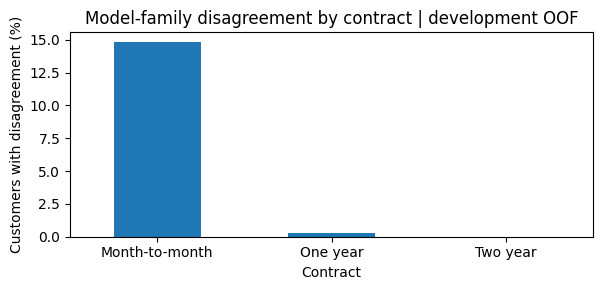

These are association summaries, not proof contract changes would improve prediction reliability.


In [17]:
atlas=raw[['customerID','Contract','InternetService','tenure','TechSupport']].merge(
    pd.DataFrame({'customerID':fold_order.to_numpy(),'family_disagreement':family_flip.to_numpy(),'prep_disagreement':prep_unstable.to_numpy()}),
    on='customerID',how='inner',validate='one_to_one')
by_contract=atlas.groupby('Contract').family_disagreement.agg(['size','sum','mean']).sort_values('mean',ascending=False)
display(by_contract.round(4))
ax=(by_contract['mean']*100).plot(kind='bar',figsize=(6,3),rot=0,title='Model-family disagreement by contract | development OOF')
ax.set_ylabel('Customers with disagreement (%)');plt.tight_layout();plt.show()
print('These are association summaries, not proof contract changes would improve prediction reliability.')

## 4 | Member 4 — Jayawardhana: historical replay, errors and business interpretation
**Responsibility:** Evaluate the recorded policy using the archived 1,409-customer predictions. Compare against simple risk ranking at equal contact capacity, quantify false alarms and missed churn, and recommend a human-reviewed next step.

**Important:** The archived test had earlier exposure; these plots are **replays** of the earlier output, not new untouched external validation. No thresholds or model panel are reselected from these results.

### 4.1 Fit the frozen three-model panel on all development rows
This notebook reconstructs new fitted model objects using the same settings. The next cell compares their predictions against the archived test probabilities **for reproducibility only**. It does **not** create a new independent test.

In [18]:
t0=time.time()
final_models={
 'Tuned_CatBoost':clone(model_defs['CatBoost']),
 'Gradient_Boosting':clone(model_defs['Gradient Boosting']),
 'Tuned_Random_Forest':clone(model_defs['Tuned Random Forest'])
}
for n,m in final_models.items():
 m.fit(X_dev,y_dev)
 print('Fitted',n,flush=True)
print('Reconstruction seconds',round(time.time()-t0,1))
test_archive=source_csv('recorded_test')
assert len(test_archive)==1409 and test_archive.customerID.is_unique
test_X=by_id.loc[test_archive.customerID,RAW_FEATURES].reset_index(drop=True)
test_y=by_id.loc[test_archive.customerID,'Churn'].eq('Yes').to_numpy().astype(int)
assert np.array_equal(test_y,test_archive.ActualChurn.to_numpy())
check_rows=[]
for n,m in final_models.items():
 new=m.predict_proba(test_X)[:,1];old=test_archive['prob_'+n].to_numpy()
 check_rows.append({'Model':n,'Max absolute probability difference':np.max(abs(new-old)),
                    'Mean absolute difference':np.mean(abs(new-old)),'Matches archived at 1e-4':np.allclose(new,old,rtol=0,atol=1e-4)})
verification=pd.DataFrame(check_rows);display(verification)
assert verification['Matches archived at 1e-4'].all(), 'Reconstructed models differ from archived values; check original packages/settings before submission'

Fitted Tuned_CatBoost


Fitted Gradient_Boosting


Fitted Tuned_Random_Forest


Reconstruction seconds 6.3


,Model,Max absolute probability difference,Mean absolute difference,Matches archived at 1e-4
0,Tuned_CatBoost,1.110223e-16,3.118070e-17,True
1,Gradient_Boosting,1.110223e-16,3.242172e-17,True
2,Tuned_Random_Forest,9.714451e-17,3.022531e-17,True


### 4.2 ROC, precision–recall and confusion matrix
- **ROC-AUC** summarizes ranking across false-positive and true-positive rates.
- **Average precision (AP)** focuses on retrieving the minority churn class; this is our primary ranking metric.
- A **confusion matrix** shows correct and incorrect yes/no predictions **at the fixed 0.35 threshold**.

**Do not confuse** a CatBoost confusion matrix with the 4-state TRIAGE vote table: the latter makes ACT/REVIEW/MONITOR/HOLD decisions.

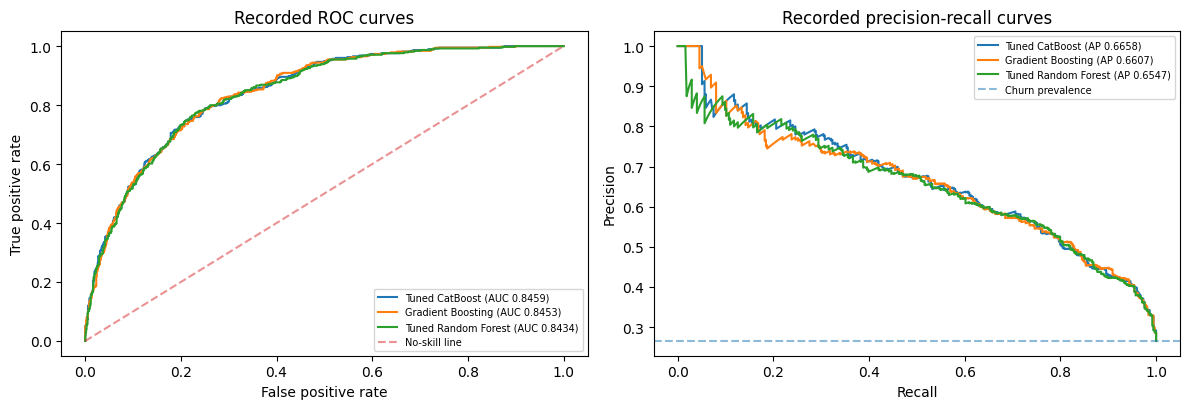

,Model,AP,ROC_AUC,Precision@.35,Recall@.35,F1@.35,TN,FP,FN,TP,Brier
0,Tuned_CatBoost,0.6658,0.8459,0.5739,0.7166,0.6373,836,199,106,268,0.1349
1,Gradient_Boosting,0.6607,0.8453,0.5711,0.7086,0.6325,836,199,109,265,0.1356
2,Tuned_Random_Forest,0.6547,0.8434,0.5702,0.7273,0.6392,830,205,102,272,0.1359


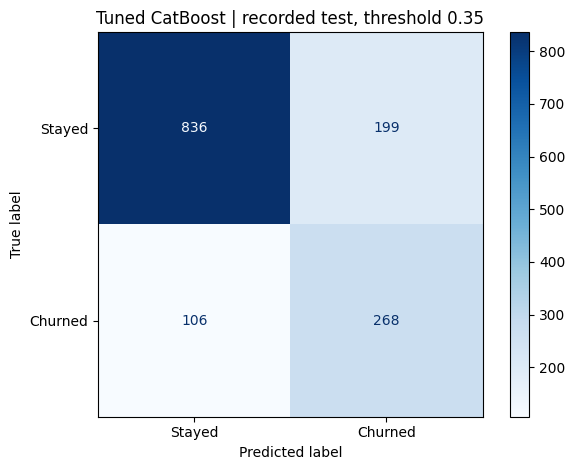

In [19]:
THRESHOLD=0.35
score_rows=[]
fig,axes=plt.subplots(1,2,figsize=(12,4.2))
for n in final_models:
 p=test_archive['prob_'+n].to_numpy();pred=(p>=THRESHOLD).astype(int)
 roc=roc_auc_score(test_y,p);ap=average_precision_score(test_y,p)
 fpr,tpr,_=roc_curve(test_y,p);precision,recall,_=precision_recall_curve(test_y,p)
 axes[0].plot(fpr,tpr,label=f'{n.replace("_"," ")} (AUC {roc:.4f})')
 axes[1].plot(recall,precision,label=f'{n.replace("_"," ")} (AP {ap:.4f})')
 tn,fp,fn,tp=confusion_matrix(test_y,pred,labels=[0,1]).ravel()
 score_rows.append([n,ap,roc,precision_score(test_y,pred),recall_score(test_y,pred),f1_score(test_y,pred),tn,fp,fn,tp,brier_score_loss(test_y,p)])
axes[0].plot([0,1],[0,1],'--',alpha=.5,label='No-skill line');axes[0].set(xlabel='False positive rate',ylabel='True positive rate',title='Recorded ROC curves')
axes[1].axhline(test_y.mean(),linestyle='--',alpha=.5,label='Churn prevalence');axes[1].set(xlabel='Recall',ylabel='Precision',title='Recorded precision-recall curves')
for a in axes:a.legend(fontsize=7)
plt.tight_layout();plt.show()
score=pd.DataFrame(score_rows,columns=['Model','AP','ROC_AUC','Precision@.35','Recall@.35','F1@.35','TN','FP','FN','TP','Brier'])
display(score.round(4))
ConfusionMatrixDisplay.from_predictions(test_y,(test_archive.prob_Tuned_CatBoost>=THRESHOLD).astype(int),
   display_labels=['Stayed','Churned'],values_format='d',cmap='Blues')
plt.title('Tuned CatBoost | recorded test, threshold 0.35');plt.tight_layout();plt.show()
assert score.loc[score.Model.eq('Tuned_CatBoost'),'TP'].item()==268
assert score.loc[score.Model.eq('Tuned_CatBoost'),'FN'].item()==106

### 4.3 Fixed operating threshold and four triage states
A probability score of **0.35 or above gives one model a positive churn vote**. Across three selected models: 3 votes = **ACT**, 2 = **REVIEW**, 1 = **MONITOR**, 0 = **HOLD**. A unanimous result **does not guarantee correctness**. Threshold 0.35 was a development trade-off, not a proven economic optimum.

In [20]:
prob_cols=['prob_Tuned_CatBoost','prob_Gradient_Boosting','prob_Tuned_Random_Forest']
votes=(test_archive[prob_cols]>=THRESHOLD).sum(axis=1).to_numpy()
state_names=np.array(['HOLD','MONITOR','REVIEW','ACT'])
states=state_names[votes];mean_prob=test_archive[prob_cols].mean(axis=1).to_numpy()
triage_df=pd.DataFrame({'customerID':test_archive.customerID,'ActualChurn':test_y,'MeanRisk':mean_prob,'PositiveVotes':votes,'TRIAGE':states})
triage_summary=triage_df.groupby('TRIAGE').ActualChurn.agg(Customers='size',ObservedChurn='sum',Rate='mean').reindex(['ACT','REVIEW','MONITOR','HOLD'])
triage_summary['Customer share']=triage_summary.Customers/len(test_y)
display(triage_summary.round(4))
assert triage_summary.Customers.to_list()==[431,43,29,906]
assert int(triage_summary.loc['HOLD','ObservedChurn'])==96
print('Important: 96 actual churners were assigned HOLD. Agreement does not mean safety.')

,Customers,ObservedChurn,Rate,Customer share
TRIAGE,,,,
ACT,431,254,0.5893,0.3059
REVIEW,43,19,0.4419,0.0305
MONITOR,29,5,0.1724,0.0206
HOLD,906,96,0.1060,0.6430


Important: 96 actual churners were assigned HOLD. Agreement does not mean safety.


### 4.4 Contact-budget test: do the TRIAGE labels improve whom we contact?
Comparison uses the **same three sets of probabilities** and ranks exactly the same number of customers. Baseline: rank by average model probability. TRIAGE: rank by state ACT → REVIEW → MONITOR → HOLD, breaking ties with mean probability. Identifying a historical churner does not establish that contacting them would prevent departure.

Capture  ... Known churners reached
Policy                           CatBoost risk ranking  ...        TRIAGE priority
Contact budget Customers reached                        ...                       
10%            140                              0.2914  ...                  106.0
20%            281                              0.5053  ...                  189.0
30%            422                              0.6631  ...                  250.0

[3 rows x 6 columns]

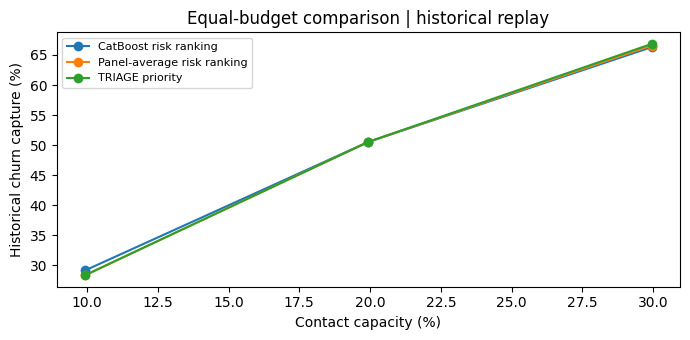

Finding: no reliable improvement in churn capture compared with ordinary ranking.


In [21]:
risk_order=np.argsort(-mean_prob,kind='stable')
state_priority=3-votes
triage_order=np.lexsort((-mean_prob,state_priority))
cb_order=np.argsort(-test_archive.prob_Tuned_CatBoost.to_numpy(),kind='stable')
rows=[]
for fraction in [.10,.20,.30]:
 k=int(len(test_y)*fraction)
 for policy,order in [('Panel-average risk ranking',risk_order),('TRIAGE priority',triage_order),('CatBoost risk ranking',cb_order)]:
  c=int(test_y[order[:k]].sum())
  rows.append({'Contact budget':f'{int(fraction*100)}%','Customers reached':k,'Policy':policy,'Known churners reached':c,'Capture':c/test_y.sum()})
budget=pd.DataFrame(rows);display(budget.pivot_table(index=['Contact budget','Customers reached'],columns='Policy',values=['Known churners reached','Capture']).round(4))
check=budget[budget.Policy.isin(['Panel-average risk ranking','TRIAGE priority'])].pivot(index='Contact budget',columns='Policy',values='Known churners reached')
assert check.loc['10%'].nunique()==1 and check.loc['20%'].nunique()==1
assert check.loc['30%','TRIAGE priority']-check.loc['30%','Panel-average risk ranking']==1
fig,ax=plt.subplots(figsize=(7,3.5))
for policy,g in budget.groupby('Policy'):
 ax.plot(g['Customers reached']/len(test_y)*100,g['Capture']*100,marker='o',label=policy)
ax.set(xlabel='Contact capacity (%)',ylabel='Historical churn capture (%)',title='Equal-budget comparison | historical replay');ax.legend(fontsize=8);plt.tight_layout();plt.show()
print('Finding: no reliable improvement in churn capture compared with ordinary ranking.')

### 4.5 Subgroup considerations and real-world limitations
Check whether ACT-only recall and false-positive rates differ across groups; these checks highlight risks rather than guaranteeing algorithmic fairness. The dataset does not include interventions, offer acceptance, retention costs, or future time stamps, so return on investment and causal retention improvement cannot be claimed.

In [22]:
profiles=raw[['customerID','gender','SeniorCitizen','Contract']].merge(triage_df,on='customerID',validate='one_to_one')
subrows=[]
for attribute in ['gender','SeniorCitizen','Contract']:
 for group,g in profiles.groupby(attribute):
  n_pos=int(g.ActualChurn.sum());n_neg=len(g)-n_pos
  subrows.append({'Attribute':attribute,'Group':str(group),'Customers':len(g),'Actual churners':n_pos,
      'ACT-only recall':(int(((g.TRIAGE=='ACT')&(g.ActualChurn==1)).sum())/n_pos if n_pos else np.nan),
      'ACT false-positive rate':(int(((g.TRIAGE=='ACT')&(g.ActualChurn==0)).sum())/n_neg if n_neg else np.nan)})
display(pd.DataFrame(subrows).round(4))
print('Subgroup rates based on small counts are noisy. No inference of causal discrimination or parity is made.')

,Attribute,Group,Customers,Actual churners,ACT-only recall,ACT false-positive rate
0,gender,Female,687,193,0.6684,0.1599
1,gender,Male,722,181,0.6906,0.1811
2,SeniorCitizen,0,1187,276,0.6377,0.1427
3,SeniorCitizen,1,222,98,0.7959,0.3790
4,Contract,Month-to-month,773,329,0.7660,0.3964
5,Contract,One year,300,36,0.0556,0.0038
6,Contract,Two year,336,9,0.0000,0.0000


Subgroup rates based on small counts are noisy. No inference of causal discrimination or parity is made.


## 5 | Consolidated decisions, evidence and recommendations
This section satisfies the group assignment requirement for a **decision log**. The full archived decisions, EDA insight log, preprocessing feature log, data dictionary, model comparison and original dataset are embedded in this single notebook (not dependent on external scripts).

**Main evidence-supported conclusions:**
1. **Data quality:** Use the unchanged 7,043-customer source; repair the 11 blank charges only in zero-tenure context.
2. **Preprocessing:** Learn category/numeric transformations inside training folds; prevent customerID/Churn leakage. Balancing and new features are compared, not blindly adopted.
3. **Model comparison:** Logistic Regression baseline + Decision Tree, Random Forest, Gradient Boosting, CatBoost; tune key settings and acknowledge Random Forest's larger training gap.
4. **Reliability:** Multiple models with similar AP can disagree for individual customers, even when they all perform reasonably well overall.
5. **Business conclusion:** Rank customers by predicted churn risk and show disagreement to a reviewer. TRIAGE is not proven to outperform simple risk ranking or increase retained customers.
6. **Limitations:** Pre-recorded test exposure, development-fold reuse in tuning, historical cross-sectional data, no interventions, unknown real contact costs, and correlations rather than causality.

In [23]:
decision_log=source_csv('decision_log')
display(decision_log)
print('Data dictionary fields:',len(dictionary),'| Decisions:',len(decision_log),'| Input predictors:',len(RAW_FEATURES))
print('Public dataset: https://www.kaggle.com/datasets/blastchar/telco-customer-churn')
print('Group project: https://github.com/Zacky-Ahmed/TRIAGE_Telco_Project')
print('The assignment also requires a separate three-minute demonstration and individual A4 learning journeys.')

,DecisionID,Stage,Question,Evidence,RecordedDecision,EvidenceFile,Owner
0,D01,M1,Preserve original raw dataset,Copied for EDA; no raw-data overwrite,Raw data remains unchanged,final_notebook_code/notebooks/member1/01_membe...,Jayasinghe
1,D02,M1->M2,Handle blank TotalCharges meaningfully,11 blanks at tenure 0; Member2 CV compared alt...,Zero imputation default in reproducible develo...,model_method_comparison/results/member2/tables...,Imani
2,D03,M2,Exclude identifiers and target-derived inputs,customerID is ID; Churn is target,Exclude from X and preserve customerID as join...,decision_logs/member2/feature_registry.csv,Imani
3,D04,M2,Compare imbalance approaches,CV: no balance vs class weights vs random over...,Keep tradeoff evidence; no balancing as defaul...,model_method_comparison/results/member2/tables...,Imani
4,D05,M2,Decide engineered-feature defaults,Ablation did not materially increase PR-AUC,"Engineered features experimental, not default",model_method_comparison/results/member2/tables...,Imani
5,D06,M2,Check demographic data necessity,Light demographic feature set similar performance,Report data-minimization comparison without fa...,model_method_comparison/results/member2/tables...,Imani
6,D07,M3,Compare baseline and multiple families,5-fold CV model scorecards and OOF,Retain credible model alternatives; do not cho...,model_method_comparison/results/member4/model_...,Ahmed
7,D08,M3+M4,Select final near-optimal panel,Tolerance sensitivity and development mean PR-AUC,"Freeze 0.010 panel: Tuned CatBoost, GB, Tuned RF",model_method_comparison/results/member3/tables...,Ahmed/Jayawardhana
8,D09,M4,Choose operating threshold,Threshold analysis and business trade-offs,T = 0.35 for final TRIAGE votes,model_method_comparison/results/member4/thresh...,Jayawardhana
9,D10,M4,Interpret mixed model votes,Review and selective coverage analyses,"ACT=3, REVIEW=2, MONITOR=1, HOLD=0 positive votes",model_method_comparison/results/member4/final_...,Jayawardhana


Data dictionary fields: 21 | Decisions: 14 | Input predictors: 19
Public dataset: https://www.kaggle.com/datasets/blastchar/telco-customer-churn
Group project: https://github.com/Zacky-Ahmed/TRIAGE_Telco_Project
The assignment also requires a separate three-minute demonstration and individual A4 learning journeys.


## 6 | Worked example: entering a new customer
Using reconstructed **fitted models**, evaluate the supplied synthetic profiles. These examples contain **no observed future churn**, so their predictions cannot show accuracy or a real retention effect. They also demonstrate that after the three models are fit, scoring an incoming record does not retrain any model.

In [24]:
example=source_csv('synthetic')
print('Synthetic example columns:',example.columns.to_list())
# A scoring interface accepts 19 fields; any optional ID is held outside the model.
if 'customerID' in example.columns:example_ids=example.customerID.copy()
else:example_ids=pd.Series([f'synthetic_{i+1}' for i in range(len(example))])
example_X=example[RAW_FEATURES].copy()
example_prob=pd.DataFrame({'customerID':example_ids})
for name,est in final_models.items():example_prob[name]=est.predict_proba(example_X)[:,1]
example_prob['PositiveVotes']=(example_prob[list(final_models)]>=THRESHOLD).sum(axis=1)
example_prob['State']=state_names[example_prob.PositiveVotes.to_numpy()]
display(example_prob.round(4))
print('These scores are illustrative from synthetic inputs, not empirical measurements of a new deployed system.')

Synthetic example columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


,customerID,Tuned_CatBoost,Gradient_Boosting,Tuned_Random_Forest,PositiveVotes,State
0,Synthetic A,0.7430,0.7331,0.7387,3,ACT
1,Synthetic B,0.0211,0.0280,0.0153,0,HOLD
2,Synthetic C,0.9210,0.8572,0.8306,3,ACT


These scores are illustrative from synthetic inputs, not empirical measurements of a new deployed system.


## 7 | End-of-notebook consistency and submission readiness
- This **one `.ipynb` file** contains all four members' ordered logic, while the accompanying dataset folder contains the original dataset and data dictionary, the saved split/folds, decisions, original experiment outputs and recorded evaluation probabilities.
- It **imports no project `.py` scripts**. All fitting, plotting and decision functions are defined inline.
- Executed result cells are saved when the notebook is delivered. If the installed ML libraries differ from the original tested versions, reconstruction checks may fail rather than silently changing reported numbers.
- The notebook is a **consolidated reproducible presentation** of the original work, not a claim that the full historical hyperparameter search, seed sweep or every archived experiment has been newly rerun inside it.
- The official final report should separately provide the three-minute YouTube URL, and each member submits an individual learning journey.

In [25]:
assert len(raw)==7043 and len(X_dev)==5634 and len(test_archive)==1409
assert set(triage_df.TRIAGE)=={'ACT','REVIEW','MONITOR','HOLD'}
assert int(family_flip.sum())==463 and int(prep_unstable.sum())==1114
assert np.isfinite(recomputed_cv.NewMeanFoldAP).all()
assert len(score)==3
print('PASS — original external CSV, split, recorded model evidence, Member 1–4 handoffs, decision policy and evaluated outputs.')
print('COMPLETE: one main IT3091 project notebook; data/evidence folders required, no external scripts required.')

PASS — original external CSV, split, recorded model evidence, Member 1–4 handoffs, decision policy and evaluated outputs.
COMPLETE: one main IT3091 project notebook; data/evidence folders required, no external scripts required.
